# 02b - See the P300 evolve over the scalp and cortex

**OpenNeuro ds003061 / sub-001 / run-1**  
A guided continuation of `02_erp_p300.ipynb`, inspired by the MNE [Visualize source time courses](https://mne.tools/stable/auto_tutorials/inverse/60_visualize_stc.html) tutorial.

**Learning goals**
1. Animate **measured scalp voltage** between 0 and 650 ms after auditory stimuli.
2. Estimate **cortical source activity** using the `fsaverage` template, a forward model and an inverse solution.
3. Interactively move through time in a 3D brain viewer.

**Important interpretation:** the scalp animation is an interpolation of measured electrode voltages. The 3D animation is *not measured cortical activation*. It is an approximate, model-dependent inverse estimate, without subject-specific MRI or digitized electrode locations. Do **not** draw precise anatomical conclusions from it. We also haven't implemented full ICA/artifact QC.

Work through the cells in order. **Part A** works without 3D packages. **Part B** downloads the template anatomy and requires a functioning 3D viewer.

## 0 - Environment and paths

Use the **Python (EEG_project)** kernel. In PowerShell, if needed, run from your root project directory:

```powershell
cd "C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
.\.venv\Scripts\python.exe -m pip install --upgrade mne numpy matplotlib ipython pillow
```

- `cd` navigates to your project root.
- `.\.venv\Scripts\python.exe` selects the project's Python interpreter explicitly.
- `-m pip install` installs packages into **that specific environment**, not another Python installation.
- The first 2D animation does **not** need PyVista.

For **Part B only**, install the 3D viewer into the same environment:

```powershell
.\.venv\Scripts\python.exe -m pip install pyvista pyvistaqt PyQt6
```

A Windows desktop with graphics support is needed for the separate 3D Qt window. The `fsaverage` dataset also requires an internet download on first use.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import mne

# Absolute path matches our existing project layout.
ROOT = Path(r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project")
DATA_ROOT = ROOT / "project1_openneuro" / "data" / "ds003061"
EEG_FILE = DATA_ROOT / "sub-001" / "eeg" / "sub-001_task-P300_run-1_eeg.set"

assert EEG_FILE.is_file(), f"EEG recording was not found: {EEG_FILE}"
print("MNE:", mne.__version__)
print("EEG file:", EEG_FILE.name)

MNE: 1.13.2
EEG file: sub-001_task-P300_run-1_eeg.set


## 1 - Load the recording and specify which channels are EEG

Unlike simply taking the first 79 signals as EEG, we explicitly retain the **64 scalp electrodes** and mark EXG, GSR, respiration, etc. as auxiliary `misc` signals.

- `read_raw_eeglab()` reads the continuous EEG into an MNE `Raw` object.
- `raw.ch_names[:64]` chooses the 64 scalp channels already inspected in Notebook 01.
- `set_channel_types()` prevents the auxiliary channels from contributing to EEG operations.
- `set_montage()` assigns template electrode positions for scalp plotting and later approximate 3D modeling.

Some MNE versions expose `fsaverage_1005`, while older versions expose `standard_1005`. We choose whichever is available. Their assumed coordinates are **not personalized measurements**. In the 3D section we'll use the fsaverage transformation and check the approximate geometry.

In [ ]:
raw = mne.io.read_raw_eeglab(EEG_FILE, preload=True, verbose=False)
scalp_channels = raw.ch_names[:64]
auxiliary_channels = [ch for ch in raw.ch_names if ch not in scalp_channels]
raw.set_channel_types({ch: "misc" for ch in auxiliary_channels})

# Use fsaverage-compatible electrode locations when supported by MNE.
try:
    montage = mne.channels.make_standard_montage("fsaverage_1005")
    montage_name = "fsaverage_1005"
except ValueError:
    montage = mne.channels.make_standard_montage("standard_1005")
    montage_name = "standard_1005 (fallback)"

raw.set_montage(montage, on_missing="raise")
print("Scalp EEG channels:", len(scalp_channels))
print("Auxiliary channels:", auxiliary_channels)
print("Template electrode montage:", montage_name)

Scalp EEG channels: 64
Auxiliary channels: ['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
Template electrode montage: fsaverage_1005


C:\Users\Fafou\AppData\Local\Temp\ipykernel_2140\3993902931.py:1: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(EEG_FILE, preload=True, verbose=False)
C:\Users\Fafou\AppData\Local\Temp\ipykernel_2140\3993902931.py:1: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(EEG_FILE, preload=True, verbose=False)
C:\Users\Fafou\AppData\Local\Temp\ipykernel_2140\3993902931.py:4: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({ch: "misc" for ch in auxiliary_channels})
C:\Users\Fafou\AppData\Local\Temp\ipykernel_2140\3993902931.py:4: 

## 2 - Filter, align to stimuli, and compute ERPs

This repeats familiar concepts from Notebook 02 but with two small changes:

- `raw.set_eeg_reference("average", projection=True)` adds the average reference as an EEG projection, the MNE-recommended setup for inverse modeling. MNE applies it when the data are processed.
- `raw.filter(l_freq=1.0, h_freq=30.0, picks="eeg")` keeps the approximate 1-30 Hz frequency range for a clearer visualization. This is **not a fully optimized ERP filter**, and the 1-Hz high-pass could affect low-frequency morphology.
- The event codes are **normalized**: standard becomes 1, and responded/unresponded oddballs become 2. That avoids the cross-run code-number mismatch we encountered earlier.
- We create `epochs` from -200 to +800 ms. `reject=dict(eeg=150e-6)` drops epochs that exceed 150 µV peak-to-peak at an EEG channel, a basic illustrative artifact check, **not** a replacement for full inspection or ICA.
- `difference_erp` represents oddball-minus-standard average voltage across the scalp.

The critical distinction is that `difference_erp` is still sensor-space data, not cortical sources.

In [ ]:
# Add average-reference projection, then filter only scalp EEG.
raw.set_eeg_reference("average", projection=True, verbose=False)
raw.filter(l_freq=1.0, h_freq=30.0, picks="eeg", verbose=False)

events, event_id = mne.events_from_annotations(raw, verbose=False)
standard_code = event_id["standard"]
oddball_codes = [
    event_id[label]
    for label in ("oddball", "oddball_with_reponse")
    if label in event_id
]
assert oddball_codes, "No oddball events were found."

is_standard = events[:, 2] == standard_code
is_oddball = np.isin(events[:, 2], oddball_codes)
selected = is_standard | is_oddball
selected_events = events[selected].copy()
selected_events[:, 2] = np.where(is_standard[selected], 1, 2)

epochs = mne.Epochs(
    raw, selected_events,
    event_id={"standard": 1, "oddball": 2},
    tmin=-0.2, tmax=0.8,
    baseline=(-0.2, 0.0),
    picks=scalp_channels,
    reject=dict(eeg=150e-6),
    preload=True, proj=True, verbose=False,
)

standard_erp = epochs["standard"].average()
oddball_erp = epochs["oddball"].average()
difference_erp = mne.combine_evoked(
    [oddball_erp, standard_erp], weights=[1, -1]
)

print("Retained standard trials:", len(epochs["standard"]))
print("Retained oddball trials:", len(epochs["oddball"]))
print("ERP channels:", len(difference_erp.ch_names))

Retained standard trials: 501
Retained oddball trials: 108
ERP channels: 64


## Part A - Animate scalp voltages over time

### 3 - Inspect several snapshots

`plot_topomap` shows the **interpolated scalp voltage distribution** at specified latencies. The `average=0.04` argument averages a 40-ms window centered on each requested time, reducing noisy single-sample fluctuations.

Color indicates oddball-minus-standard voltage in µV. **A positive region is not automatically a cortical generator underneath it.**

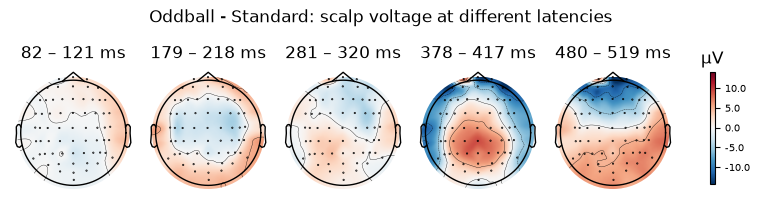

In [ ]:
fig = difference_erp.plot_topomap(
    times=[0.10, 0.20, 0.30, 0.40, 0.50],
    average=0.04,
    time_unit="ms",
    sensors=True,
    colorbar=True,
    show=False,
)
fig.suptitle("Oddball - Standard: scalp voltage at different latencies")
display(fig)
plt.close(fig)

### 4 - Animate the topography from 0 to 650 ms

- `np.arange(0.0, 0.65, 0.025)` requests a frame every 25 ms.
- `animate_topomap()` generates a Matplotlib animation from the measured-sensor ERP.
- `to_jshtml()` embeds interactive playback controls **directly in VS Code's notebook output**, without installing Qt/PyVista.
- `blit=False` is more robust for notebook embedding.

Use the playback controls under the figure to see the response evolve. This is the easiest and most defensible first visualization.

In [5]:
frame_times = np.arange(0.0, 0.651, 0.025)
fig, animation = difference_erp.animate_topomap(
    times=frame_times,
    frame_rate=12,
    butterfly=False,
    blit=False,
    show=False,
)

# HTML playback with a time slider in the notebook.
display(HTML(animation.to_jshtml()))
plt.close(fig)

C:\Users\Fafou\AppData\Local\Temp\ipykernel_2140\2859406039.py:2: RuntimeWarning: More than 25 topomaps plots requested. This might take a while.
  fig, animation = difference_erp.animate_topomap(


## Part B - Estimate cortical source activity (optional, more demanding)

**What changes:** scalp voltage is not the same quantity as brain-source activity. To estimate generators we need a **forward model** (what scalp fields hypothetical cortical currents would produce), a **noise covariance estimate**, and an **inverse operator** (a regularized estimate of currents given the scalp data).

We use MNE's `fsaverage` template anatomy, not this participant's MRI. Localization could be off by centimeters, and any apparently focal hot spot may be strongly affected by assumptions or artifacts. The resulting `SourceEstimate` is for demonstration and visualization rather than scientific localization claims.

First-run download can be large. The next cells can take a while and require the 3D packages mentioned above.

### 5 - Fetch the template MRI and its precomputed models

- `fetch_fsaverage()` gets the standard FreeSurfer brain and prepared head models, caching them locally.
- `src` is the cortical source-space grid (candidate source points).
- `bem` represents how brain, skull and scalp tissues conduct electric fields.
- `trans="fsaverage"` uses MNE's built-in coordinate transform for the template geometry.

For a source model, electrode/head geometry **must** be reasonably aligned. The following optional alignment plot helps catch obvious mistakes (requires the 3D backend).

In [6]:
from mne.datasets import fetch_fsaverage

fs_dir = Path(fetch_fsaverage(verbose=True))
subjects_dir = fs_dir.parent
subject = "fsaverage"
trans = "fsaverage"
src = fs_dir / "bem" / "fsaverage-ico-5-src.fif"
bem = fs_dir / "bem" / "fsaverage-5120-5120-5120-bem-sol.fif"

print("Template folder:", fs_dir)
print("Source space exists:", src.exists())
print("BEM exists:", bem.exists())

Using default location ~/mne_data for montage coregistration...
Creating C:\Users\Fafou\mne_data
Attempting to create new mne-python configuration file:
C:\Users\Fafou\.mne\mne-python.json
Could not read the C:\Users\Fafou\.mne\mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
179 files missing from root.txt in C:\Users\Fafou\mne_data\MNE-fsaverage-data


c:\Users\Fafou\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|########################################| 196M/196M [00:00<00:00, 249GB/s]


Extracting missing files
Successfully extracted 179 files
10 files missing from bem.txt in C:\Users\Fafou\mne_data\MNE-fsaverage-data\fsaverage


100%|########################################| 239M/239M [00:00<00:00, 307GB/s]


Extracting missing files
Successfully extracted 10 files
Template folder: C:\Users\Fafou\mne_data\MNE-fsaverage-data\fsaverage
Source space exists: True
BEM exists: True


### 6 - (Recommended) Check approximate EEG alignment with the template

Run this **only when the 3D backend is working**. Check whether electrodes lie near the template scalp rather than far inside/outside it.

`plot_alignment()` does not make the template individualized; it simply lets us inspect geometry. If it looks wrong, **stop rather than trusting the source reconstruction**.

In [7]:
# Optional geometry inspection - requires PyVista/Qt on Windows.
# Skip this cell if you only want the scalp animation.

alignment = mne.viz.plot_alignment(
    epochs.info,
    subject="fsaverage",
    subjects_dir=str(subjects_dir),
    src=src,
    trans=trans,
    eeg=["original", "projected"],
    mri_fiducials=True,
    dig="fiducials",
    show_axes=True,
)

Reading C:\Users\Fafou\mne_data\MNE-fsaverage-data\fsaverage\bem\fsaverage-ico-5-src.fif...


RuntimeError: Could not load any valid 3D backend
pyvistaqt: No module named 'qtpy'
notebook: No module named 'ipyevents'

 install pyvistaqt, using pip or conda:
'pip install pyvistaqt'
'conda install -c conda-forge pyvistaqt'

 or install ipywidgets, if using a notebook backend
'pip install ipywidgets'
'conda install -c conda-forge ipywidgets'

### 7 - Estimate the baseline noise covariance

The inverse solution needs to know how much and what kind of noise is present in the EEG channels.

`compute_covariance()` calculates channel-by-channel noise covariance from the **pre-stimulus interval** (-200 to 0 ms), across our retained epochs. `method="shrunk"` regularizes the covariance, which can help when many channels are correlated. Because we only did minimal artifact QC, this estimate is exploratory.

In [ ]:
noise_cov = mne.compute_covariance(
    epochs, tmin=-0.2, tmax=0.0,
    method="shrunk", rank=None, verbose=False,
)
print(noise_cov)

### 8 - Build the forward model and estimate sources

- `make_forward_solution()` calculates how hypothetical activity at each template cortical location would propagate to our 64 scalp electrodes.
- `make_inverse_operator()` calculates a regularized mapping from EEG to source space, using the forward model and measured baseline covariance.
- `apply_inverse()` applies that mapping to our **oddball-minus-standard ERP**, producing a `SourceEstimate` (`stc`).
- `method="dSPM"` gives noise-normalized source estimates. Colors are *not* scalp voltage and should not be labeled in µV.
- `lambda2 = 1/9` corresponds to a nominal signal-to-noise ratio of 3 used as a common tutorial setting; it is not independently calibrated for this recording.

This calculation is the technically demanding step. If forward modeling fails due to mismatched geometry, do not force it: return to the alignment figure and inspect channel positions.

In [ ]:
from mne.minimum_norm import make_inverse_operator, apply_inverse

forward = mne.make_forward_solution(
    epochs.info,
    trans=trans,
    src=src,
    bem=bem,
    meg=False,
    eeg=True,
    mindist=5.0,
    n_jobs=1,
    verbose=True,
)

inverse = make_inverse_operator(
    epochs.info,
    forward,
    noise_cov,
    loose=0.2,
    depth=0.8,
    verbose=True,
)

stc = apply_inverse(
    difference_erp,
    inverse,
    lambda2=1.0 / 9.0,
    method="dSPM",
    verbose=True,
)

print(stc)

### 9 - Interactively scrub estimated source activity on a 3D brain

This is the [MNE source visualization](https://mne.tools/stable/auto_tutorials/inverse/60_visualize_stc.html) concept you linked: `stc.plot()` renders the source time course on the cortical surface. `time_viewer=True` opens time controls; `initial_time=0.35` starts near the expected P300.

On Windows this will usually open a **separate Qt 3D window** when `pyvistaqt` and a Qt binding are installed. If it fails with an OpenGL or backend error, the Part A scalp animation remains usable. Color indicates **estimated source strength (dSPM score)**, not a direct measurement of the underlying neural current or proof of its location.

In [ ]:
brain = stc.plot(
    subject="fsaverage",
    subjects_dir=str(subjects_dir),
    hemi="split",
    views="lateral",
    surface="inflated",
    initial_time=0.35,
    time_viewer=True,
    smoothing_steps=5,
    size=(1000, 550),
    background="white",
    foreground="black",
    backend="pyvistaqt",
)

# Move the slider in the new 3D window to browse 0-650 ms.

## Interpretation checklist

**What can I legitimately say?**

- The **scalp animation** shows when/where oddball-minus-standard voltages vary across the **recorded electrodes**.
- The **3D animation** shows estimated source contributions **conditional on the chosen template, forward model, covariance, inverse regularization and reference**.
- A strong scalp signal at Pz does **not** prove that a single cortical structure directly underneath Pz generated it.
- A participant with a stronger response in one run is not automatically a stronger auditory neural responder: trial counts, noise, reference and task performance matter.

**Good next experiments:** add more participants/runs, compare standard versus oddball animations, apply artifact QC/ICA, examine time-averaged dSPM patterns between ~300 and 450 ms, and compare model behavior across subjects.

**Version-control note:** commit this `.ipynb` to GitHub, but do not add raw EEG, downloaded `fsaverage` anatomy, or rendered movies without considering their size and provenance.

### MNE references

- [Visualize source time courses (STCs)](https://mne.tools/stable/auto_tutorials/inverse/60_visualize_stc.html)
- [EEG forward operator with template MRI](https://mne.tools/stable/auto_tutorials/forward/35_eeg_no_mri.html)
- [Source localization and dSPM inverse solution](https://mne.tools/stable/auto_tutorials/inverse/30_mne_dspm_loreta.html)